# Detección de cáncer cutáneo

Vamos a usar un dataset público almacenado en Kaggle para enseñar a un model de IA a clasificar imágenes de la piel, indicando si en ellas se muestra un lunar benigno o maligno. El dataset se encuentra almacenado en:

https://www.kaggle.com/datasets/fanconic/skin-cancer-malignant-vs-benign

Las imágenes del dataset (todas en color y con una resolución de 224x224 pixels) ya están organizadas en tres carpetas: "data", "test", y "train".

La carpeta "train" se utiliza para entrenar el modelo, y la carpeta "test" se utiliza para comprobar si el modelo ha aprendido algo (contiene imágenes que no han sido utilizadas durante el entrenamiento). La carpeta "data" almacena todas las imágenes (las de entrenamiento y las de test). Ignorarla.

## Paso 1. Descargar el dataset

Indica el siguiente prompt a Gemini:

```
Crea una celda para descargar el dataset

https://www.kaggle.com/datasets/fanconic/skin-cancer-malignant-vs-benign

y crear un enlace simbólico hasta él desde la carpeta

/content
```

En Google Colab el usuario almacena sus ficheros en la carpeta `/content`. Un enlace simbólico es un "link" hacia una carpeta o o archivo (no se copia nada, sólo es una especie de alias).

In [1]:
import os
import kagglehub

# Descargar la última versión del dataset
path = kagglehub.dataset_download("fanconic/skin-cancer-malignant-vs-benign")
print("Dataset descargado en:", path)

# Definir la ruta del enlace simbólico
symlink_path = "/content/skin-cancer-malignant-vs-benign"

# Eliminar el enlace simbólico o archivo existente si ya existe para evitar el FileExistsError
if os.path.exists(symlink_path) or os.path.islink(symlink_path):
    os.unlink(symlink_path)

# Crear el enlace simbólico
os.symlink(path, symlink_path)
print(f"Enlace simbólico creado con éxito en: {symlink_path}")

Using Colab cache for faster access to the 'skin-cancer-malignant-vs-benign' dataset.
Dataset descargado en: /kaggle/input/skin-cancer-malignant-vs-benign
Enlace simbólico creado con éxito en: /content/skin-cancer-malignant-vs-benign


Si exporamos el dataset, veremos que cada carpeta ("test" y "train") está a su vez organizada en 2 sub-carpetas llamadas "benign" y "malignant". Esta información será utilizada durante el entrenamiento del modelo.

## Paso 2. Indicamos qué imágenes usaremos para entrenar el modelo y cómo las vamos a usar

Para entrenar vamos a dividir las imágenes en 3 conjuntos:

1. Imágenes de `train` (entrenamiento): Son las que el modelo ve y estudia para aprender patrones visuales y ajustar sus parámetros internos (como los pesos de una red neuronal). Suelen ocupar la mayor parte del conjunto de datos (por ejemplo, un 70%).

2. Imágenes de `validation` (validación): Sirven para medir el rendimiento del modelo durante el desarrollo, ajustar hiperparámetros (tasa de aprendizaje, arquitectura, epochs), elegir la mejor versión y detectar sobreajuste (overfitting). El modelo no entrena directamente con ellas, pero tú sí tomas decisiones sobre el modelo según sus resultados.

3. Imágenes de `test` (prueba): Actúan como el examen final. Se mantienen ocultas durante todo el entrenamiento y ajuste, y se evalúan al final para estimar cómo rendirá el modelo con imágenes nuevas en condiciones reales.

Además, usando Tensorflow deberemos indicar qué porcentaje de imágenes dedicaremos a entrenamiento y validación. En concreto, vamos a usar un 80% de las imágenes para entrenar y un 20% para validación.

Finalmente, también debemos decidir el "batch_size" que define cuántas imágenes vamos a usar durante una iteración de entrenamiento. Un valor razonable sería 32 porque: (1) no consume mucha memoria (los "lotes" se cargan desde disco a memoria para ser usados), (2) no va a tardar mucho/iteración (así podremos ver con más frecuencia cómo va evolucionando (aprendiendo) el modelo, y (3) el algoritmo de aprendizaje ([SGD](https://en.wikipedia.org/wiki/Stochastic_gradient_descent)) va a evolucionar de forma suave (valores muy pequeños tienen a provocar un aprendizaje más herrático).

Indica el siguiente prompt a Gemini:

```
Usando Tensorflow, crea una celda para indicar dónde están las imágenes de `training`
(/content/skin-cancer-malignant-vs-benign/train), `validation`
(/content/skin-cancer-malignant-vs-benign/train), y `test`
(/content/skin-cancer-malignant-vs-benign/test).
Utiliza el 80% de las imágenes para entrenamiento.
Recuerda que las imágenes tienen 224x224 pixels.
Usa un tamaño de lote igual a 32.
```

In [2]:
import tensorflow as tf

# Rutas de los directorios
train_dir = "/content/skin-cancer-malignant-vs-benign/train"
test_dir = "/content/skin-cancer-malignant-vs-benign/test"

# Parámetros comunes
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
SEED = 42

# 1. Dataset de Entrenamiento (80% de las imágenes de la carpeta train)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

# 2. Dataset de Validación (20% de las imágenes de la carpeta train)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

# 3. Dataset de Test
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

# Mostrar información de las clases encontradas
class_names = train_ds.class_names
print("Clases detectadas:", class_names)

Found 2637 files belonging to 2 classes.
Using 2110 files for training.
Found 2637 files belonging to 2 classes.
Using 527 files for validation.
Found 660 files belonging to 2 classes.
Clases detectadas: ['benign', 'malignant']


### (Opcional) Caching, prefeching, y shuffling

Cuando se utilizan datasets que caben en la memoria RAM, y con el objeto de reducir la lecturas a disco, se puede activar opción "prefech" para mantener el dataset en la memoria RAM de la computadora mientras se realiza el entrenamiento.

Por otro lado, el prefeching configura Tensorflow para solapar (posibles) cálculos en paralelo en la CPU y la GPU (si esta está disponible).

Finalmente, suelen obtenerse entrenamientos más robustos (el modelo tiende a clasificar mejor) si las imágenes del dataset no son usadas siempre en el mismo orden. A esta opción se le conoce como "shuffling" (barajado).

En general, si olvidas este paso, el modelo va a aprender igual, aunque probablmente tarde más y es posible que si no activas el shuffling, obtengas un entrenamiento subóptimo.

Indica el siguiente prompt a Gemini:

```
Activa el prefecning y cacheo del dataset (train_ds, val_ds y test_ds).
Usa un suffling de 1000 imágenes para acceder a train_ds.
```


In [3]:
# Configurar buffer de prefetch automático
AUTOTUNE = tf.data.AUTOTUNE

# Aplicar caché, barajado (shuffle) y precarga (prefetch) en train_ds
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)

# Aplicar caché y precarga (prefetch) en val_ds y test_ds
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Configuración de caching, prefetching y shuffling completada con éxito.")

Configuración de caching, prefetching y shuffling completada con éxito.


## Paso 3. Definición (de la arquitectura) del modelo

Usar un modelo de IA para clasificar imágenes implica definir su arquitectura y luego entrenarlo. Lo primero no es trivial, y lo segundo, puede llevar mucho tiempo y requerir ingentes cantidades de imágenes.

Por suerte, ya existen modelos entrenados que distinguen muy bien, por ejemplo, entre perros y gatos. Uno de estos modelos es MovileNet2, que además forma parte de Keras (el interface de programación de alto nivel para TensorFlow que estamos usando). Por tanto, lo que vamos a hacer es aplicar una técnica de programación en IA que se conoce como "Fine-Tuning", que consiste en especializar un modelo ya pre-entrenado (en el caso de nuestro modelo MobileNet2, con más de un millón de imágenes pertenecientes al dataset ImageNet) para clasificar en nuestro caso, fotos de lunares.

En un "Ajuste Fino", sólo la(s) última(s) capa(s) (de neuronas artificiales) se re-entrena (el resto de capas permanecen "congeladas") con el dataset en cuestión. En el caso de Keras, cuando instanciemos (inicialicemos) el modelo, deberemos especificar que las últimas capas no deben usarse (van a ser reemplazadas por otras más adecuadas para nuestra clasificación binaria). En el modelo MobileNet2, estas últimas capas de usan para clasificar entre unas 1000 clases, entre las que se incluyen perros, coches o sillas.

Indica el siguiente prompt a Gemini:

```
Importa MobileNetV2 de Keras e instancialo con los pesos obtenidos tras entrenarlo con ImageNet para clasificar imágenes RGB con shape 224x224. Descarta las últimas capas para poder más tarde redefinirlas y realizar un fine-tuning del modelo.
```

In [4]:
from tensorflow.keras.applications import MobileNetV2

# Definimos las dimensiones de entrada de la imagen (224x224 píxeles y 3 canales de color RGB)
input_shape = (224, 224, 3)

# Instanciamos el modelo base MobileNetV2 preentrenado en ImageNet
# Al poner include_top=False, descartamos la última capa de clasificación (las últimas capas)
base_model = MobileNetV2(
    input_shape=input_shape,
    include_top=False,
    weights='imagenet'
)

# Congelamos los pesos del modelo base para que no se modifiquen durante el entrenamiento inicial
base_model.trainable = False

# Mostramos un resumen del modelo base
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## Paso 4. Indicamos la entrada al modelo para su entrenamiento

Ahora conectamos el modelo con las imágenes, para que intente clasificarlas en "benignas" o "malignas", y en el caso de que se equivoque, reentrenar sólo las últimas capas (que definiremos a continuación).

Para hacer esto tenemos que hacer casar el formato en que la información está almacenada en las imágenes con el formato en que el modelo procesa dicha información. MobileNet2 (al igual que la inmensa mayoría de los modelos) procesa sólo valores entre [-1, 1], mientras que cada canal (R, G o B) de nuestras imágenes toma valores entre [0, 255]. Por este motivo, en Keras, necesitamos crear una capa de tipo "Input" que realice dicha adaptación.

Indica el siguiente prompt a Gemini:

```
Define una capa de tipo "Input" para adaptar las imágenes RGB con shape 224x224 al formato esperado por la primera capa de base_model. Recuerda que base_model no debe ser entrenado.
```

In [5]:
# 1. Definimos la capa de entrada con la forma de la imagen (224, 224, 3)
inputs = tf.keras.Input(shape=(224, 224, 3))

# 2. Aplicamos la función de preprocesamiento específica de MobileNetV2
# Esto escala de forma óptima los valores de los píxeles de [0, 255] al rango [-1, 1]
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# 3. Pasamos las imágenes preprocesadas a través del modelo base que está congelado
x = base_model(x, training=False)

print("Capa de entrada y preprocesamiento de MobileNetV2 definidos con éxito.")

Capa de entrada y preprocesamiento de MobileNetV2 definidos con éxito.


## Paso 5. Añadimos las capas para la clasificación binaria

Si nos fijamos en la salida del Paso 3, el shape de la última capa es (7, 7, 1280). Para reducir toda esa información en un único número entre 0 (lunar 100% benigno) y 1 (lunar 100% maligno), vamos a añadir una capa de promediado de los tensores de 7x7, con lo que pasaremos a tener 1280 "rasgos", luego añadiremos una capa de "Dropout" para ignorar el 20% de las neuronas durante el entrenamiento de dicha capa (esto reduce el riesgo de que el modelo memorice las imágenes (overfitting), y finalmente, añadiremos una última capa "densa" con una única neurona de salida que usará la función de activación "sigmoid", garantizando así un valor de salida del modelo entre 0 y 1.

Indica el siguiente prompt a Gemini:

```
Añade a "x" una capa de promediado 2D para pasar los tensores con shape 7x7x1280 a tensores con shape 1x1280. A continuación añade una capa de Dropout al 20%, y finalmente añade una capa densa con una única neurona activada mediante "sigmoid".
```

In [6]:
# 4. Añadimos la capa de promediado global 2D para pasar de 7x7x1280 a 1280 rasgos
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# 5. Añadimos una capa de Dropout al 20% para regularización
x = tf.keras.layers.Dropout(0.2)(x)

# 6. Añadimos la capa densa final con activación 'sigmoid' para la predicción de clase binaria (0 o 1)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

print("Capas de clasificación añadidas correctamente sobre 'x'.")

Capas de clasificación añadidas correctamente sobre 'x'.


## Paso 6. Instancia el modelo y define su I/O

Hemos definido la arquitectura del modelo, pero aún no existe (hay que "instanciarlo").

Indica el siguiente prompt a Gemini:

```
Instancia el modelo.
```

In [7]:
# Instanciamos el modelo final de Keras conectando la entrada original con la salida final
model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Mostramos un resumen del modelo completo para ver la estructura final
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Paso 7. "Compilamos" el modelo

En Keras el modelo debe compilarse, que no es otra cosa que definir qué optimizador y métrica de error vamos a utilizar y con qué tasa de aprendizaje.

Indica el siguiente prompt a Gemini:

```
Compila el modelo. Usa el optimizador "Adam" y un learning rate de 10^-4. Como función de pérdida utiliza la entropía cruzada binaria.
```

In [8]:
# Compilamos el modelo utilizando el optimizador Adam y la pérdida de entropía cruzada binaria
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Modelo compilado con éxito.")

Modelo compilado con éxito.


## Paso 8. Entrena el modelo.

Entrenamos nuestro modelo durante 10 épocas (10 pasadas sobre el dataset de entrenamiento). Si tu entorno de ejecución dispone de una GPU (por ejemplo, una [NVIDIA T4](https://www.nvidia.com/en-us/data-center/tesla-t4/)), este paso tardará sólo unos segundos.

Indica el siguiente prompt a Gemini:

```
Entrena el modelo. Utiliza 10 épocas.
```

In [9]:
# Entrenamos el modelo durante 10 épocas utilizando los datasets de entrenamiento y validación
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 66s 828ms/step - accuracy: 0.4664 - loss: 0.8248 - val_accuracy: 0.5446 - val_loss: 0.7214
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 72s 817ms/step - accuracy: 0.5957 - loss: 0.6898 - val_accuracy: 0.6641 - val_loss: 0.6246
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 82s 825ms/step - accuracy: 0.6730 - loss: 0.6049 - val_accuracy: 0.7116 - val_loss: 0.5688
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 54s 816ms/step - accuracy: 0.7270 - loss: 0.5513 - val_accuracy: 0.7306 - val_loss: 0.5348
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 52s 794ms/step - accuracy: 0.7611 - loss: 0.5115 - val_accuracy: 0.7476 - val_loss: 0.5111
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 806ms/step - accuracy: 0.7711 - loss: 0.4901 - val_accuracy: 0.7647 - val_loss: 0.4952
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 799ms/step - accuracy: 0.7782 - loss: 0.4794 - val_accuracy: 0.7685 - val_loss: 0.4815
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 53s 802ms/step - accuracy: 0.7972 - loss: 0.4525 - val_accu

In [ ]:
# Evaluamos el modelo utilizando el dataset de prueba (test_ds)
loss, accuracy = model.evaluate(test_ds)

print(f"Pérdida (Loss) final en Test: {loss:.4f}")
print(f"Precisión (Accuracy) final en Test: {accuracy:.4f}")

## Paso 9. Evaluamos el rendimiento del modelo

Veamos, por fin, el "accuracy" conseguido con nuestro modelo sobre las imágenes de test. Recuerda que el accuracy mide la proporción de predicciones correctas que hace un modelo respecto al total de predicciones realizadas.

Indica el siguiente prompt a Gemini:

```
Evalúa el modelo entrenado usando test_ds e imprime la pérdida y precisión final.
```

In [10]:
# Evaluamos el modelo entrenado usando el dataset de prueba
loss, accuracy = model.evaluate(test_ds)

print(f"Precisión (Accuracy) final en Test: {accuracy:.4f}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 14s 640ms/step - accuracy: 0.8152 - loss: 0.4110
Precisión (Accuracy) final en Test: 0.8152


## Paso 10. Visualizamos qué está pasando

Indica el siguiente prompt a Gemini:

```
Muestra algunas de las imágenes correctamente clasificadas e incorrectamente clasificadas.
```

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 676ms/step


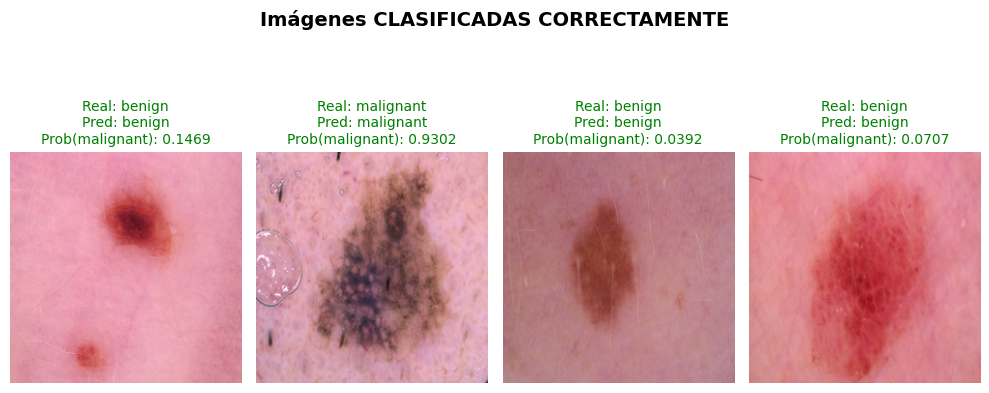

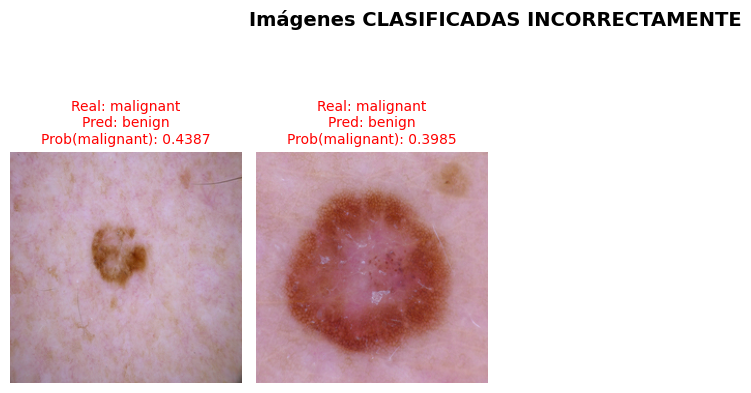

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener un lote (batch) de imágenes y etiquetas reales del dataset de prueba
for images, labels in test_ds.take(1):
    test_images = images.numpy()
    test_labels = labels.numpy()
    break

# 2. Realizar las predicciones con el modelo entrenado
predictions = model.predict(test_images).flatten()
# Dado que usamos activación sigmoide, la predicción es 1 si la probabilidad >= 0.5, sino 0
predicted_labels = (predictions >= 0.5).astype(int)

# 3. Clasificar los índices en aciertos y fallos
correct_indices = np.where(predicted_labels == test_labels)[0]
incorrect_indices = np.where(predicted_labels != test_labels)[0]

# Mapear los índices numéricos a los nombres de las clases
class_map = {0: 'benign', 1: 'malignant'}

# 4. Mostrar clasificaciones correctas
plt.figure(figsize=(10, 5))
plt.suptitle("Imágenes CLASIFICADAS CORRECTAMENTE", fontsize=14, fontweight='bold')
for i, idx in enumerate(correct_indices[:4]):
    plt.subplot(1, 4, i + 1)
    img = test_images[idx].astype("uint8")
    plt.imshow(img)
    # Mostramos la etiqueta real, la predicha y la probabilidad obtenida
    plt.title(f"Real: {class_map[test_labels[idx]]}\nPred: {class_map[predicted_labels[idx]]}\nProb(malignant): {predictions[idx]:.4f}", color='green', fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

# 5. Mostrar clasificaciones incorrectas (si existen en el lote)
if len(incorrect_indices) > 0:
    plt.figure(figsize=(10, 5))
    plt.suptitle("Imágenes CLASIFICADAS INCORRECTAMENTE", fontsize=14, fontweight='bold')
    for i, idx in enumerate(incorrect_indices[:4]):
        plt.subplot(1, 4, i + 1)
        img = test_images[idx].astype("uint8")
        plt.imshow(img)
        # Mostramos la etiqueta real, la predicha y la probabilidad obtenida
        plt.title(f"Real: {class_map[test_labels[idx]]}\nPred: {class_map[predicted_labels[idx]]}\nProb(malignant): {predictions[idx]:.4f}", color='red', fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("¡Excelente! No hubo clasificaciones incorrectas en este lote de prueba.")

##